# Escolha do Modelo

Neste projeto, testamos três modelos para classificar os documentos: **Random Forest**, **SVM** e **XGBoost**.

Optamos por seguir com o **XGBoost** pelos seguintes motivos:

* **Desempenho e estabilidade:** Foi o modelo que apresentou o melhor equilíbrio nas métricas entre as três classes, sem puxar viés para a classe majoritária.
* **Controle de sobreajuste (overfit):** Como nossas variáveis são binárias (0 ou 1 para presença de palavras), usamos árvores rasas 'max_depth=3', taxa de aprendizado baixa 'learning_rate=0.01' e 'gamma=1'. Isso fez o modelo focar apenas nas palavras que realmente diferenciam os documentos, evitando que ele decorasse a base.
* **Comparação com os outros:** O SVM exigiu mais transformações nos dados para convergir e a Random Forest oscilou um pouco mais nos testes. O XGBoost lidou melhor com as features do OCR direto na pipeline.
* **Integração com a API:** O modelo é bem leve e rápido na inferência, o que facilita colocar para rodar no backend com FastAPI e nos devolve direto a probabilidade da previsão.


# Instalar dependencias

In [ ]:
import os
import joblib
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import LabelEncoder

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Carregar dados

In [ ]:
url_csv = "https://raw.githubusercontent.com/MarcosJn08/Analise_RG/refs/heads/main/Dataset/Feature/features.csv"
df = pd.read_csv(url_csv)
X = df[
    [
    "Identidade",
    "Carteira de Identidade",
    "Registro Geral",
    "CPF",
    "Nome",
    "Filiação",
    "Data de Nascimento",
    "Naturalidade",
    "Nacionalidade",
    "Sexo",
    "Órgão Expedidor",
    "Data de Expedição",
    "SSP",
    "Polegar Direito",
    "Assinatura do Titular",
    "Válida em todo território nacional",
    "Carteira de Identidade Nacional",
    "Identidade Nacional",
    "Validade",
    "República Federativa do Brasil",
    "National Identity Card",
    "Identity Card",
    "Name",
    "Date of Birth",
    "Place of Birth",
    "Nationality",
    ]
]

y = df.categoria

from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()
y = encoder.fit_transform(df["categoria"])

# Separar treino e teste

In [ ]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

# **Modelo XGBoost**

In [ ]:
from xgboost import XGBClassifier

In [ ]:
modeloXGB = make_pipeline(
    SimpleImputer(strategy="median"),
    XGBClassifier(
        objective="multi:softprob",
        n_estimators=300,
        max_depth=3,
        learning_rate=0.01,
        gamma=1,
        random_state=42,
        eval_metric="mlogloss",
    )
)

modeloXGB.fit(X_treino, y_treino)
joblib.dump(modeloXGB, "modelo_xgboost.joblib")
previsoesXGB = modeloXGB.predict(X_teste).astype(int)

# Avaliar modelo

Acurácia: 96.2617

Relatório de classificação:
              precision    recall  f1-score   support

   Invalidos       0.97      1.00      0.98        60
   RG_Antigo       0.96      0.90      0.93        30
     RG_novo       0.94      0.94      0.94        17

    accuracy                           0.96       107
   macro avg       0.96      0.95      0.95       107
weighted avg       0.96      0.96      0.96       107



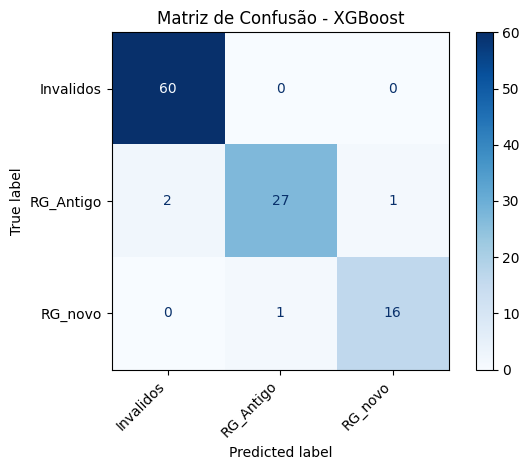

In [ ]:

print("Acurácia:", round(100*accuracy_score(y_teste, previsoesXGB), 4))

print("\nRelatório de classificação:")
print(classification_report(
    y_teste,
    previsoesXGB,
    labels=list(range(len(encoder.classes_))),
    target_names=encoder.classes_,
    zero_division=0
))

matriz = confusion_matrix(
    y_teste,
    previsoesXGB,
    labels=list(range(len(encoder.classes_)))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=encoder.classes_
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de Confusão - XGBoost")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
